# Multilayer Perceptron for Classification using Sequential API

_**Use sequential API to build and train a multiclass image classifier model, perform classification, and evaluate performance.**_

In [22]:
# Imports packages

import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay

import torch
import torch.nn as nn
import torchvision.transforms.v2 as transforms_v2
from torchvision.datasets import FashionMNIST
from torch.utils.data import Subset, DataLoader

import matplotlib.pyplot as plt
from tqdm import tqdm

## Data Ingestion & Transformation
This experiments uses the fashion MNIST dataset that is already shuffled and split between a training set (60,000 images) and a test set (10,000 images).

In [2]:
# Defines required transformations to be applied on the dataset
transform = transforms_v2.Compose([
    transforms_v2.ToImage(),                            # Converts to tensor, only needed for PIL images
    transforms_v2.ToDtype(torch.float32, scale=True),   # Requires only for normalization that expects float input
])

In [3]:
# Initializes the dataset objects
train_set_full = FashionMNIST(
    root="./../../data/",     # Root directory of dataset where FashionMNIST/raw/train-images-idx3-ubyte and FashionMNIST/raw/t10k-images-idx3-ubyte exist
    train=True,               # If 'True', loads train set, otherwise test set
    transform=transform,      # Takes in PIL images and returns transformed versions
    download=False            # Loads dataset from the root directory instead of downloading
    )

test_set = FashionMNIST(
    root="./../../data/",
    train=False,
    transform=transform,
    download=False
    )

## Analyzing the Dataset



In [4]:
# Checks the full training set size
print("Full train dataset shape:", train_set_full.data.shape)
print("Test dataset shape:", test_set.data.shape)

Full train dataset shape: torch.Size([60000, 28, 28])
Test dataset shape: torch.Size([10000, 28, 28])


In [5]:
train_set_full.classes  # Lists all the item classes

['T-shirt/top',
 'Trouser',
 'Pullover',
 'Dress',
 'Coat',
 'Sandal',
 'Shirt',
 'Sneaker',
 'Bag',
 'Ankle boot']

In [6]:
train_set_full.targets      # Class indexes for all items

tensor([9, 0, 0,  ..., 3, 0, 5])

In [7]:
train_set_full.data.dtype   # Checks the value range for each pixel in the image (i.e. 0-255 if `uint8`)

torch.uint8

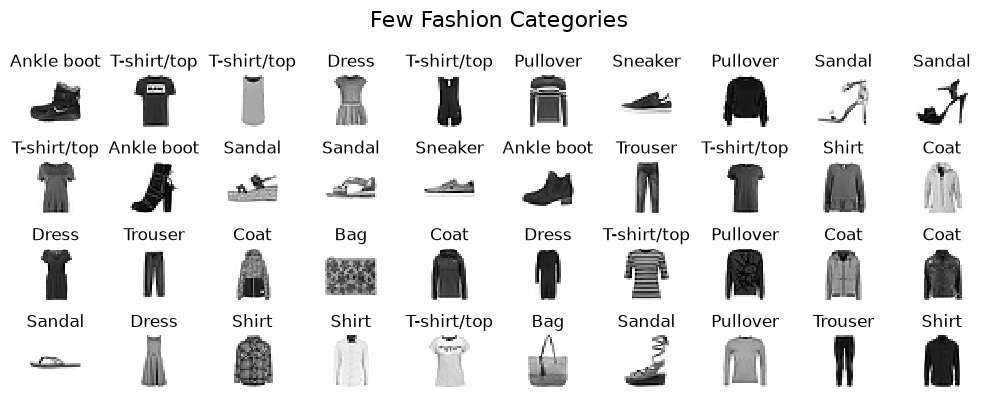

In [8]:
# Displays few of the items with their classes

n_rows = 4
n_cols = 10

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols, n_rows))
axes = axes.flatten()                                     # Flattens the 2D array of axes to 1D for easier iteration
for idx, image in enumerate(train_set_full.data[:40]):    # Iterates through the sample images to plot them
    axes[idx].imshow(image, cmap="binary", interpolation="nearest")             # Displays the image in the corresponding subplot
    axes[idx].set_title(train_set_full.classes[train_set_full.targets[idx]])    # Sets the title of the subplot to the image label
    axes[idx].axis("off")                                 # Hides the axis for a cleaner look

plt.suptitle("Few Fashion Categories", fontsize=16)       # Sets a main title for the entire figure
plt.tight_layout()                                        # Adjusts layout to prevent overlap
plt.show()         

## Data Preparation

In [9]:
# Seperates validation (20%) set from full training set by splitting it stratifically on its labels/targets

train_idx, val_idx = train_test_split(
    np.arange(len(train_set_full.data)), 
    test_size=5000,  # 20% of the full training set
    random_state=42, 
    stratify=train_set_full.targets
    )

train_set = Subset(train_set_full, train_idx)
val_set = Subset(train_set_full, val_idx)

train_set.indices, val_set.indices

(array([24934, 10272, 17372, ..., 21465, 35819, 13937], shape=(55000,)),
 array([46615,  4357,  6698, ..., 14257, 56477, 46683], shape=(5000,)))

In [10]:
# Creates data loaders

BATCH_SIZE = 256     # For number of samples to go through the model network at once

train_loader = DataLoader(
    train_set,                  # Dataset from which to load the data.
    batch_size=BATCH_SIZE,  # Number of samples per batch to load (default: 1)
    shuffle=True,           # If `True`, the data gets reshuffled at every epoch (default: False).
    )

val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False)

## Modeling

In [11]:
# Checks if the system supports CUDA (to use GPU for computations)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using {device}")

Using cpu


In [12]:
torch.manual_seed(42)   # For code to produces the exact same results (random number sequence) every time it is run

# Initializes the model and moves to the device
model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28*28, 300),
    nn.ReLU(),
    nn.Linear(300, 100),
    nn.ReLU(),
    nn.Linear(100, 10)
).to(device)

print(model)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=300, bias=True)
  (2): ReLU()
  (3): Linear(in_features=300, out_features=100, bias=True)
  (4): ReLU()
  (5): Linear(in_features=100, out_features=10, bias=True)
)


## Model Training

In [13]:
loss_fn = nn.CrossEntropyLoss()                             # Sets the loss function
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)  # Sets the optimizer

In [14]:
len(val_loader.dataset)

5000

In [15]:
def test(dataloader, model, loss_fn, device):
    num_samples = len(dataloader.dataset) # The total number of items in the dataset
    num_batches = len(dataloader)         # The number of steps in one full epoch
    cumulative_loss, true_predictions = 0, 0

    model.eval()                    # Switches network from training mode to evaluation mode

    with torch.no_grad():  # Turns off the autograd engine to save memory and accelerate computations
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            predictions = model(X)
            cumulative_loss += loss_fn(predictions, y).item()
            average_loss = cumulative_loss / num_batches
            true_predictions += (predictions.argmax(1) == y).type(torch.float).sum().item()
            average_accuracy = true_predictions / num_samples
            
    return average_loss, average_accuracy   # Returns average loss and accuracy (in percentile)

In [16]:
def train(train_loader, model, loss_fn, optimizer, device, val_loader=None):
    """
    Trains the model over one epoch.
    """

    # num_samples = len(train_set_loader.dataset)   # Total number of samples in the dataset
    num_batches = len(train_loader)
    cumulative_loss = 0
    num_samples_worked_on = 0
    true_predictions = 0

    model.train()                                   # Sets the model in training mode

    with tqdm(range(num_batches)) as progbar:
        for step_idx, (X, y) in enumerate(train_loader):
            X, y = X.to(device), y.to(device)

            # Forward pass
            predictions = model(X)             # Model performs prediction
            loss = loss_fn(predictions, y)     # Computes prediction error
    
            # Backpropagation
            optimizer.zero_grad()   # Clear existing gradients from the previous step
            loss.backward()         # Compute gradients via backpropagation
            optimizer.step()        # Update model weights based on computed gradients

            # Statistics

            cumulative_loss += loss.item() * len(X)
            num_samples_worked_on += len(X)

            average_loss = cumulative_loss/num_samples_worked_on
            true_predictions += (predictions.argmax(1) == y).type(torch.float).sum().item()
            average_accuracy = true_predictions/num_samples_worked_on

            progbar.set_postfix({"loss": average_loss, "accuracy": average_accuracy})
            progbar.update(1)

        if val_loader is not None:
            val_loss, val_accuracy = test(val_loader, model, loss_fn, device)
            progbar.set_postfix({"loss": average_loss, "accuracy": average_accuracy, "val_loss": val_loss, "val_accuracy": val_accuracy})
            return average_loss, average_accuracy, val_loss, val_accuracy

    return average_loss, average_accuracy

In [17]:
train_history = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": []}

EPOCHS = 10

for epoch in range(EPOCHS):
    print(f"Epoch {epoch+1}/{EPOCHS}")
    average_loss, average_accuracy, val_loss, val_accuracy = train(train_loader, model, loss_fn, optimizer, device, val_loader)
    train_history["loss"].append(average_loss)
    train_history["accuracy"].append(average_accuracy)
    train_history["val_loss"].append(val_loss)
    train_history["val_accuracy"].append(val_accuracy)

Epoch 1/10


100%|██████████| 215/215 [00:10<00:00, 20.80it/s, loss=0.672, accuracy=0.769, val_loss=0.437, val_accuracy=0.852]


Epoch 2/10


100%|██████████| 215/215 [00:09<00:00, 22.12it/s, loss=0.43, accuracy=0.849, val_loss=0.371, val_accuracy=0.869]


Epoch 3/10


100%|██████████| 215/215 [00:09<00:00, 21.59it/s, loss=0.38, accuracy=0.865, val_loss=0.36, val_accuracy=0.87]


... (10 outputs left out)

Epoch 9/10


100%|██████████| 215/215 [00:06<00:00, 32.87it/s, loss=0.272, accuracy=0.899, val_loss=0.3, val_accuracy=0.894]


Epoch 10/10


100%|██████████| 215/215 [00:06<00:00, 32.56it/s, loss=0.263, accuracy=0.903, val_loss=0.286, val_accuracy=0.896]


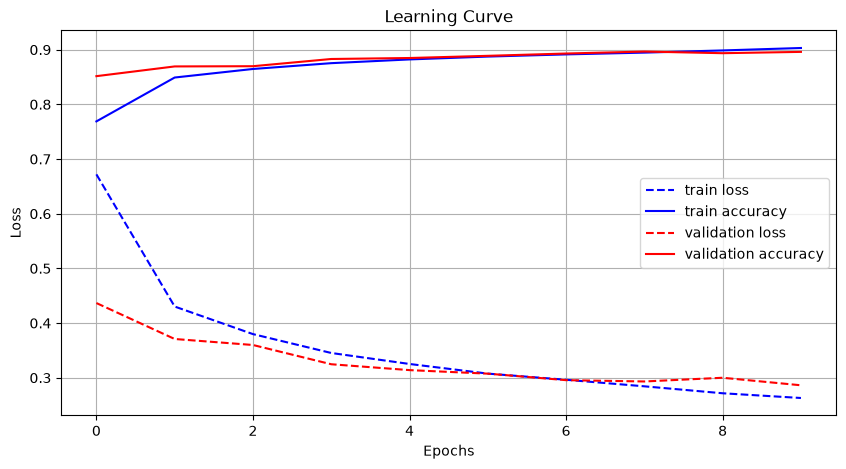

In [18]:
# Visualizing the learning curves of the model

plt.figure(figsize=(10,5))  # Sets width and height of the figure in inches

# Plots the train loss, train accuracy, val. loss and val. accuracy over epochs

plt.plot(train_history["loss"], "b--", label="train loss")
plt.plot(train_history["accuracy"], "b-", label="train accuracy")
plt.plot(train_history["val_loss"], "r--", label="validation loss")
plt.plot(train_history["val_accuracy"], "r-", label="validation accuracy")

plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.grid()
plt.legend()
plt.title("Learning Curve")

plt.show()

## Performance Evaluation

**Making predictions for a batch**

In [19]:
X_test, y_test = next(iter(test_loader))

predictions = model(X_test.to(device)).argmax(1)   # Makes predictions for the first batch
predictions = predictions.detach().cpu()         # Moves tensor from GPU memory to CPU memory.

predicted_classes = [test_set.classes[prediction] for prediction in predictions]
true_classes = [test_set.classes[true_class] for true_class in y_test]

print(f"Batch size: {len(X_test)}, Incorrect predictions: {(predictions != y_test).sum()}")

Batch size: 256, Incorrect predictions: 30


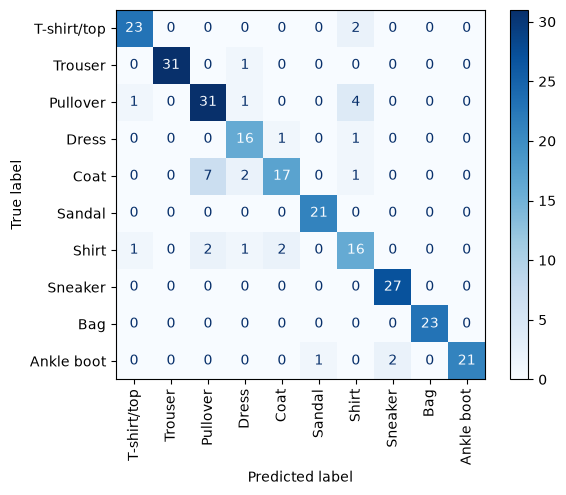

In [20]:
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions, display_labels=test_set.classes, xticks_rotation="vertical", cmap=plt.cm.Blues
)
plt.show()

**Evaluating the model over entire test set**

In [21]:
test_loss, test_accuracy = test(test_loader, model, loss_fn, device)
print(f"\ntest. loss: {test_loss:>7f} - test. accuracy: {test_accuracy:>7f}")


test. loss: 0.335564 - test. accuracy: 0.881800
